# Deep Reinforcement Learning Laboratory

In this laboratory session we will work on getting more advanced versions of Deep Reinforcement Learning algorithms up and running. Deep Reinforcement Learning is **hard**, and getting agents to stably train can be frustrating and requires quite a bit of subtlety in analysis of intermediate results. We will start by refactoring (a bit) my implementation of `REINFORCE` on the [Cartpole environment](https://gymnasium.farama.org/environments/classic_control/cart_pole/). 

## Exercise 1: Improving my `REINFORCE` Implementation (warm up)

In this exercise we will refactor a bit and improve some aspects of my `REINFORCE` implementation. 

**First Things First**: Spend some time playing with the environment to make sure you understand how it works.

### Standard imports

In [1]:
import random
import numpy as np
import torch
import gymnasium as gym
import matplotlib.pyplot as plt

from src.policy import PolicyNet, ValueNet
from src.reinforce import reinforce
from src.viz import animate_episode, plot_evaluation

SEED = 45

**Next Things Next**: Now get your `REINFORCE` implementation working on the environment. You can import my (probably buggy and definitely inefficient) implementation here. Or even better, refactor an implementation into a separate package from which you can `import` the stuff you need here.

**Last Things Last**: My implementation does a **super crappy** job of evaluating the agent performance during training. The running average is not a very good metric. Modify my implementation so that every $N$ iterations (make $N$ an argument to the training function) the agent is run for $M$ episodes in the environment. Collect and return: (1) The average **total** reward received over the $M$ iterations; and (2) the average episode length. Analyze the performance of your agents with these new metrics.

Stato iniziale: [0.00102289 0.02793397 0.02961133 0.0094755 ]
Observation space: Box([-4.8               -inf -0.41887903        -inf], [4.8               inf 0.41887903        inf], (4,), float32)
Action space: Discrete(2)
Dopo un'azione casuale -> stato: [ 0.00158156  0.22261901  0.02980084 -0.27371958] | reward: 1.0 | terminated: False | truncated: False


ALSA lib confmisc.c:855:(parse_card) cannot find card '0'
ALSA lib conf.c:5205:(_snd_config_evaluate) function snd_func_card_inum returned error: No such file or directory
ALSA lib confmisc.c:422:(snd_func_concat) error evaluating strings
ALSA lib conf.c:5205:(_snd_config_evaluate) function snd_func_concat returned error: No such file or directory
ALSA lib confmisc.c:1342:(snd_func_refer) error evaluating name
ALSA lib conf.c:5205:(_snd_config_evaluate) function snd_func_refer returned error: No such file or directory
ALSA lib conf.c:5728:(snd_config_expand) Evaluate error: No such file or directory
ALSA lib pcm.c:2722:(snd_pcm_open_noupdate) Unknown PCM default


Episodio durato 10 step
Episode 25 | avg reward: 12.0 | avg length: 12.0
Episode 50 | avg reward: 10.3 | avg length: 10.3
Episode 75 | avg reward: 11.8 | avg length: 11.8
Episode 100 | avg reward: 11.7 | avg length: 11.7
Episode 125 | avg reward: 17.0 | avg length: 17.0
Episode 150 | avg reward: 25.1 | avg length: 25.1
Episode 175 | avg reward: 49.3 | avg length: 49.3
Episode 200 | avg reward: 38.4 | avg length: 38.4
Episode 225 | avg reward: 27.2 | avg length: 27.2
Episode 250 | avg reward: 97.6 | avg length: 97.6
Episode 275 | avg reward: 103.7 | avg length: 103.7
Episode 300 | avg reward: 127.1 | avg length: 127.1
Episode 325 | avg reward: 91.6 | avg length: 91.6
Episode 350 | avg reward: 42.0 | avg length: 42.0
Episode 375 | avg reward: 65.1 | avg length: 65.1
Episode 400 | avg reward: 149.8 | avg length: 149.8
Episode 425 | avg reward: 157.6 | avg length: 157.6
Episode 450 | avg reward: 213.9 | avg length: 213.9
Episode 475 | avg reward: 262.9 | avg length: 262.9
Episode 500 | avg

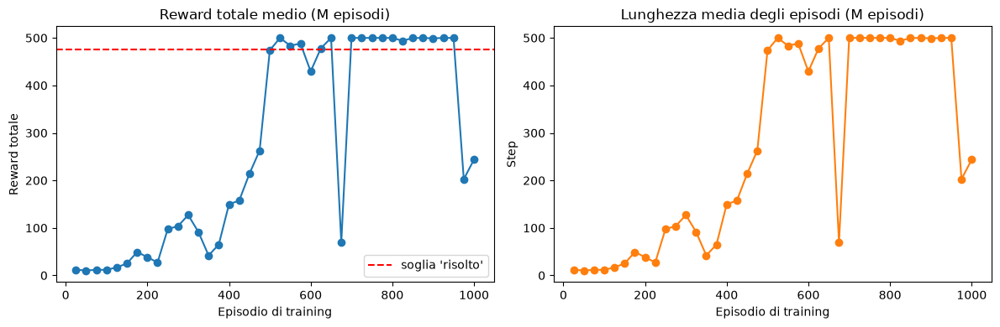

ALSA lib confmisc.c:855:(parse_card) cannot find card '0'
ALSA lib conf.c:5205:(_snd_config_evaluate) function snd_func_card_inum returned error: No such file or directory
ALSA lib confmisc.c:422:(snd_func_concat) error evaluating strings
ALSA lib conf.c:5205:(_snd_config_evaluate) function snd_func_concat returned error: No such file or directory
ALSA lib confmisc.c:1342:(snd_func_refer) error evaluating name
ALSA lib conf.c:5205:(_snd_config_evaluate) function snd_func_refer returned error: No such file or directory
ALSA lib conf.c:5728:(snd_config_expand) Evaluate error: No such file or directory
ALSA lib pcm.c:2722:(snd_pcm_open_noupdate) Unknown PCM default


Episodio durato 215 step


In [2]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

env = gym.make("CartPole-v1")
env.reset(seed=SEED)
env.action_space.seed(SEED)


state, info = env.reset()
print("Stato iniziale:", state)
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)

state, reward, terminated, truncated, info = env.step(env.action_space.sample())
print(f"Dopo un'azione casuale -> stato: {state} | reward: {reward} | "
      f"terminated: {terminated} | truncated: {truncated}")

animate_episode("CartPole-v1")


policy = PolicyNet(env)
eval_episodes, eval_rewards, eval_lengths = reinforce(env, policy, num_episodes=1000, N=25, M=10)


fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(eval_episodes, eval_rewards, marker="o")
ax1.axhline(env.spec.reward_threshold, color="red", linestyle="--", label="soglia 'risolto'")
ax1.set(title="Reward totale medio (M episodi)", xlabel="Episodio di training", ylabel="Reward totale")
ax1.legend()
ax2.plot(eval_episodes, eval_lengths, marker="o", color="tab:orange")
ax2.set(title="Lunghezza media degli episodi (M episodi)", xlabel="Episodio di training", ylabel="Step")
plt.tight_layout()
plt.show()

animate_episode("CartPole-v1", policy)

-----
## Exercise 2: `REINFORCE` with a Value Baseline (warm up)

In this exercise we will augment my implementation (or your own) of `REINFORCE` to subtract a baseline from the target in the update equation in order to stabilize (and hopefully speed-up) convergence. For now we will stick to the Cartpole environment.



**First Things First**: Recall from the slides on Deep Reinforcement Learning that we can **subtract** any function that doesn't depend on the current action from the q-value without changing the (maximum of our) objecttive function $J$:  

$$ \nabla J(\boldsymbol{\theta}) \propto \sum_{s} \mu(s) \sum_a \left( q_{\pi}(s, a) - b(s) \right) \nabla \pi(a \mid s, \boldsymbol{\theta}) $$

In `REINFORCE` this means we can subtract from our target $G_t$:

$$ \boldsymbol{\theta}_{t+1} \triangleq \boldsymbol{\theta}_t + \alpha (G_t - b(S_t)) \frac{\nabla \pi(A_t \mid s, \boldsymbol{\theta})}{\pi(A_t \mid s, \boldsymbol{\theta})} $$

Since we are only interested in the **maximum** of our objective, we can also **rescale** our target by any function that also doesn't depend on the action. A **simple baseline** which is even independent of the state -- that is, it is **constant** for each episode -- is to just **standardize rewards within the episode**. So, we **subtract** the average return and **divide** by the variance of returns:

$$ \boldsymbol{\theta}_{t+1} \triangleq \boldsymbol{\theta}_t + \alpha \left(\frac{G_t - \bar{G}}{\sigma_G}\right) \nabla  \pi(A_t \mid s, \boldsymbol{\theta}) $$

This baseline is **already** implemented in my implementation of `REINFORCE`. Experiment with and without this standardization baseline and compare the performance. We are going to do something more interesting.

Episode 25 | avg reward: 56.5 | avg length: 56.5
Episode 50 | avg reward: 198.0 | avg length: 198.0
Episode 75 | avg reward: 288.5 | avg length: 288.5
Episode 100 | avg reward: 206.2 | avg length: 206.2
Episode 125 | avg reward: 378.7 | avg length: 378.7
Episode 150 | avg reward: 197.4 | avg length: 197.4
Episode 175 | avg reward: 376.4 | avg length: 376.4
Episode 200 | avg reward: 223.4 | avg length: 223.4
Episode 225 | avg reward: 200.8 | avg length: 200.8
Episode 250 | avg reward: 420.3 | avg length: 420.3
Episode 275 | avg reward: 500.0 | avg length: 500.0
Episode 300 | avg reward: 500.0 | avg length: 500.0
Episode 325 | avg reward: 500.0 | avg length: 500.0
Episode 350 | avg reward: 500.0 | avg length: 500.0
Episode 375 | avg reward: 159.3 | avg length: 159.3
Episode 400 | avg reward: 124.5 | avg length: 124.5
Episode 425 | avg reward: 117.3 | avg length: 117.3
Episode 450 | avg reward: 415.2 | avg length: 415.2
Episode 475 | avg reward: 500.0 | avg length: 500.0
Episode 500 | avg

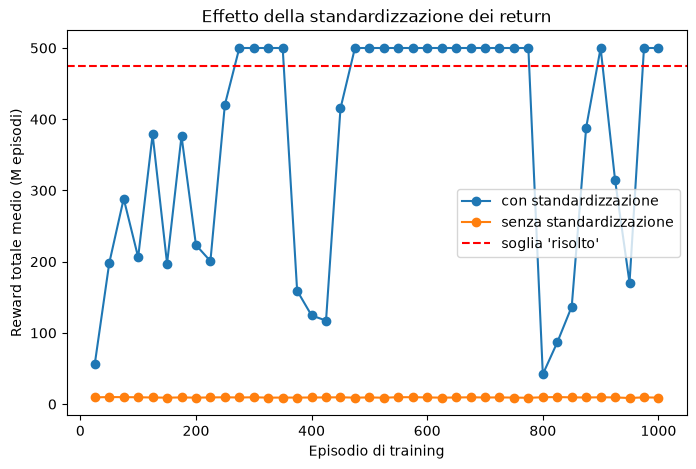

In [3]:
def train(standardize, value_baseline=False):
    """Allena una nuova policy partendo dalle stesse condizioni (stesso seed per pesi e ambiente)."""
    torch.manual_seed(SEED)
    env.reset(seed=SEED)
    policy = PolicyNet(env)
    value_net = ValueNet(env) if value_baseline else None
    return reinforce(env, policy, num_episodes=1000, N=25, M=10,
                     standardize=standardize, value_net=value_net)


episodes, rewards_std, _ = train(standardize=True)
_, rewards_raw, _ = train(standardize=False)

plt.figure(figsize=(8, 5))
plt.plot(episodes, rewards_std, marker="o", label="con standardizzazione")
plt.plot(episodes, rewards_raw, marker="o", label="senza standardizzazione")
plt.axhline(env.spec.reward_threshold, color="red", linestyle="--", label="soglia 'risolto'")
plt.xlabel("Episodio di training")
plt.ylabel("Reward totale medio (M episodi)")
plt.title("Effetto della standardizzazione dei return")
plt.legend()
plt.show()

**The Real Exercise**: Standard practice is to use the state-value function $v(s)$ as a baseline. This is intuitively appealing -- we are more interested in updating out policy for returns that estimate the current **value** worse. Our new update becomes:

$$ \boldsymbol{\theta}_{t+1} \triangleq \boldsymbol{\theta}_t + \alpha (G_t - \tilde{v}(S_t \mid \mathbf{w})) \frac{\nabla \pi(A_t \mid s, \boldsymbol{\theta})}{\pi(A_t \mid s, \boldsymbol{\theta})} $$

where $\tilde{v}(s \mid \mathbf{w})$ is a **deep neural network** with parameters $w$ that estimates $v_\pi(s)$. What neural network? Typically, we use the **same** network architecture as that of the Policy.

**Your Task**: Modify your implementation to fit a second, baseline network to estimate the value function and use it as **baseline**.

Episode 25 | avg reward: 29.1 | avg length: 29.1
Episode 50 | avg reward: 79.1 | avg length: 79.1
Episode 75 | avg reward: 70.3 | avg length: 70.3
Episode 100 | avg reward: 152.1 | avg length: 152.1
Episode 125 | avg reward: 381.6 | avg length: 381.6
Episode 150 | avg reward: 480.7 | avg length: 480.7
Episode 175 | avg reward: 500.0 | avg length: 500.0
Episode 200 | avg reward: 209.0 | avg length: 209.0
Episode 225 | avg reward: 500.0 | avg length: 500.0
Episode 250 | avg reward: 500.0 | avg length: 500.0
Episode 275 | avg reward: 500.0 | avg length: 500.0
Episode 300 | avg reward: 181.3 | avg length: 181.3
Episode 325 | avg reward: 95.1 | avg length: 95.1
Episode 350 | avg reward: 119.1 | avg length: 119.1
Episode 375 | avg reward: 257.9 | avg length: 257.9
Episode 400 | avg reward: 277.5 | avg length: 277.5
Episode 425 | avg reward: 401.9 | avg length: 401.9
Episode 450 | avg reward: 486.1 | avg length: 486.1
Episode 475 | avg reward: 500.0 | avg length: 500.0
Episode 500 | avg rewar

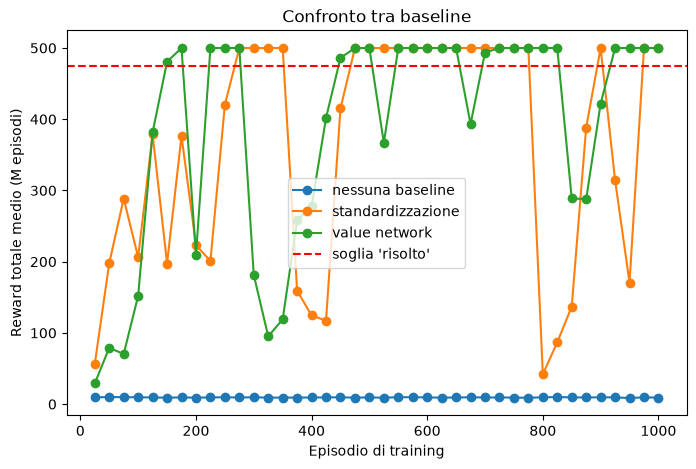

In [4]:
_, rewards_value, _ = train(standardize=False, value_baseline=True)

plt.figure(figsize=(8, 5))
plt.plot(episodes, rewards_raw, marker="o", label="nessuna baseline")
plt.plot(episodes, rewards_std, marker="o", label="standardizzazione")
plt.plot(episodes, rewards_value, marker="o", label="value network")
plt.axhline(env.spec.reward_threshold, color="red", linestyle="--", label="soglia 'risolto'")
plt.xlabel("Episodio di training")
plt.ylabel("Reward totale medio (M episodi)")
plt.title("Confronto tra baseline")
plt.legend()
plt.show()

-----
## Exercise 3: Going Deeper

As usual, pick **AT LEAST ONE** of the following exercises to complete.

### Exercise 3.1: Solving Lunar Lander with `REINFORCE` (easy)

Use my (or even better, improve on my) implementation of `REINFORCE` to solve the [Lunar Lander Environment](https://gymnasium.farama.org/environments/box2d/lunar_lander/). This environment is a little bit harder than Cartpole, but not much. Make sure you perform the same types of analyses we did during the lab session to quantify and qualify the performance of your agents.

### Exercise 3.2: Solving Cartpole and Lunar Lander with `Deep Q-Learning` (harder)

On policy Deep Reinforcement Learning tends to be **very unstable**. Write an implementation (or adapt an existing one) of `Deep Q-Learning` to solve our two environments (Cartpole and Lunar Lander). To do this you will need to implement a **Replay Buffer** and use a second, slow-moving **target Q-Network** to stabilize learning.

### Exercise 3.3: Solving the OpenAI CarRacing environment (hardest) 

Use `Deep Q-Learning` -- or even better, an off-the-shelf implementation of **Proximal Policy Optimization (PPO)** -- to train an agent to solve the [OpenAI CarRacing](https://github.com/andywu0913/OpenAI-GYM-CarRacing-DQN) environment. This will be the most *fun*, but also the most *difficult*. Some tips:

1. Make sure you use the `continuous=False` argument to the environment constructor. This ensures that the action space is **discrete** (we haven't seen how to work with continuous action spaces).
2. Your Q-Network will need to be a CNN. A simple one should do, with two convolutional + maxpool layers, folowed by a two dense layers. You will **definitely** want to use a GPU to train your agents.
3. The observation space of the environment is a single **color image** (a single frame of the game). Most implementations stack multiple frames (e.g. 3) after converting them to grayscale images as an observation.



Stato iniziale: [ 0.00357904  1.4110224   0.36249912  0.00454291 -0.00414041 -0.08211146
  0.          0.        ]
Observation space: Box([ -2.5        -2.5       -10.        -10.         -6.2831855 -10.
  -0.         -0.       ], [ 2.5        2.5       10.        10.         6.2831855 10.
  1.         1.       ], (8,), float32)
Action space: Discrete(4)
Soglia 'risolto': 200
Episodio durato 109 step
Episode 200 | avg reward: -105.6 | avg length: 89.7
Episode 400 | avg reward: -46.1 | avg length: 142.9
Episode 600 | avg reward: -12.6 | avg length: 117.0
Episode 800 | avg reward: -92.5 | avg length: 771.5
Episode 1000 | avg reward: 10.1 | avg length: 767.3
Episode 1200 | avg reward: 62.8 | avg length: 748.6
Episode 1400 | avg reward: 115.5 | avg length: 877.5
Episode 1600 | avg reward: 159.6 | avg length: 379.6
Episode 1800 | avg reward: 200.6 | avg length: 607.2
Episode 2000 | avg reward: 145.5 | avg length: 715.9
Episode 2200 | avg reward: 196.1 | avg length: 635.9
Episode 2400 | avg 

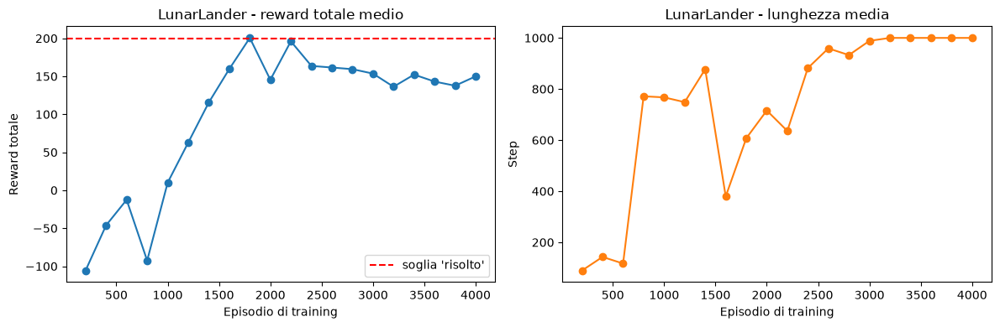

Episodio durato 1000 step


In [5]:
# Esercizio 3.1 - L'ambiente LunarLander
env_lunar = gym.make("LunarLander-v3")
state, info = env_lunar.reset(seed=SEED)
print("Stato iniziale:", state)
print("Observation space:", env_lunar.observation_space)
print("Action space:", env_lunar.action_space)
print("Soglia 'risolto':", env_lunar.spec.reward_threshold)

animate_episode("LunarLander-v3")  # episodio con azioni casuali


# Training: REINFORCE con value network come baseline
torch.manual_seed(SEED)
env_lunar.reset(seed=SEED)
policy_lunar = PolicyNet(env_lunar)
value_net_lunar = ValueNet(env_lunar)
episodes_lunar, rewards_lunar, lengths_lunar = reinforce(
    env_lunar, policy_lunar, num_episodes=4000, lr=3e-3, N=200, M=10,
    standardize=False, value_net=value_net_lunar,
)


# Metriche di valutazione
plot_evaluation(episodes_lunar, rewards_lunar, lengths_lunar,
                threshold=env_lunar.spec.reward_threshold, title="LunarLander")


# L'agente allenato
animate_episode("LunarLander-v3", policy_lunar)